# KPP–Fisher in 1-D

This example assembles the Carleman matrix of KPP–Fisher on a line from **88** element calls,
whatever the grid size, and checks the result against a direct nonlinear solve. An element call is
one `matrix[bra, ket]` lookup, which is the only thing the library computes.

Reaction–diffusion on a line, discretised on $n$ sites with spacing $h$:

$$\frac{\partial u}{\partial t}=D\,\frac{\partial^{2}u}{\partial x^{2}}+Q\,u+R\,u^{2}
\qquad\longrightarrow\qquad
\frac{du_i}{dt}=\frac{D\,(u_{i-1}-2u_i+u_{i+1})}{h^{2}}+Q\,u_i+R\,u_i^{2}$$

:::{seealso}
- [Vocabulary and symbols](../../docs/concepts.md) defines bra, ket, site, coupling, stencil,
  acting site and the symbols $A$, $K$, $M$ and $\boldsymbol\Phi$.
- [`kpp_fisher_2d`](kpp_fisher_2d.ipynb) runs the same code in 2-D.
- [`05_matrix`](../tutorials/05_matrix.ipynb) shows the plain workflow on small grids.
:::

$R\,u_i^{2}$ is the nonlinearity. Carleman linearization (**CL**) removes it by enlarging the state:
carry every monomial $\prod_s u_s^{\alpha_s}$ of total degree $\le K$, which obeys a linear
$\dot{\boldsymbol\Phi}=A\boldsymbol\Phi$.

`lin_ode` returns any single element of $A$ in closed form. It does not say which elements are
nonzero, nor which are equal.

At $n=36$, $K=3$ that matrix is $9139\times9139$, so asking for all $8.4\times10^{7}$ elements is
not an option.

This notebook derives both facts from the equation above, reproducing Fig. 3 of
[arXiv:2508.01640](https://arxiv.org/pdf/2508.01640).

In [1]:
import time

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from matplotlib import cm
from scipy.sparse import csc_matrix, csr_matrix
from scipy.sparse.linalg import expm_multiply
from scipy.integrate import solve_ivp

from lin_ode.basis import CarlemanBasis, CarlemanState
from lin_ode import OperatorMatrix
from lin_ode.operators import Koopman
from lin_ode import OrdinaryDifferentialSystem
from collections.abc import Iterator

from lin_ode.vector import Vector

D, Q, R, h = sp.symbols("D Q R h", positive=True)
u = sp.IndexedBase("u")  # field symbol; the basis supplies only the sites and powers

# lin_ode takes a grid site as its plain coordinate tuple, so a site *is* its coordinates.
# coord() exists only because lin_ode reports a 1-D site as a bare scalar i, not (i,).


def coord(label):  # site label -> integer coordinate tuple (wraps the bare 1-D scalar)
    return tuple(int(v) for v in label) if isinstance(label, (sp.Tuple, tuple)) else (int(label),)


def as_monomial(*factors):  # CarlemanState((site, power), ...) -> u[site]**power * ...
    return sp.Mul(*[u[coord(site)] ** power for site, power in factors])

StateLabel = tuple[tuple[int, int], ...]  # a state, as its (site, power) factors
CanonicalFactors = tuple[tuple[tuple[int, ...], int], ...]  # ((coordinates, power), ...), sorted
CouplingKey = tuple[CanonicalFactors, CanonicalFactors]  # (bra, ket), what classify_by_shift returns

**Nonzero entries (`find_reachable_bras`).** Label a ket by its occupation $\boldsymbol\alpha$:
$\alpha_s\ge0$ is the power at site $s$, and $\lvert\boldsymbol\alpha\rvert=\sum_s\alpha_s\le K$.

$$\lvert\boldsymbol\alpha\rangle=\prod_s u_s^{\alpha_s},\qquad
M[\boldsymbol\beta,\boldsymbol\alpha]=\langle\boldsymbol\beta\rvert\,L\,\lvert\boldsymbol\alpha\rangle,
\qquad L=\sum_s f_s(u)\,\partial_{u_s}.$$

$\partial_{u_s}$ vanishes unless $\alpha_s\ge1$, so only occupied sites act, and each term of $f_s$
sends the ket to exactly one other. Writing $\mathbf e_s$ for one unit of power at $s$:

| term of $f_s$ | bra reached | value | when |
|---|---|---|---|
| diffusion $D\,u_{s'}\partial_{u_s}$ | $\boldsymbol\alpha-\mathbf e_s+\mathbf e_{s'}$ | $\alpha_s D/h^2$ | $\alpha_s>0$, $s'\sim s$ |
| on-site $\bigl(Q-2dD/h^{2}\bigr)u_s\partial_{u_s}$ | $\boldsymbol\alpha$ | $\sum_s\alpha_s\bigl(Q-2dD/h^2\bigr)$ | $\alpha_s>0$ |
| reaction $R\,u_s^2\partial_{u_s}$ | $\boldsymbol\alpha+\mathbf e_s$ | $\alpha_s R$ | $\alpha_s>0$, $\lvert\boldsymbol\alpha\rvert<K$ |
| anything else | — | $0$ | — |

$s'\sim s$ are the $\pm1$ neighbours along each of the $d$ axes, and the equation drops the
neighbours that fall off the grid, which is the Dirichlet end.

`find_reachable_bras` returns the union of the first three rows. Every bra outside that union gives
$M=0$, and `build` discards the bras inside it that still evaluate to $0$.

In [2]:
def as_factors(state: CarlemanState) -> StateLabel:
    """A CarlemanState as canonical (coordinate-tuple, power) factors."""
    return tuple((coord(label), int(power)) for label, power in state.args)


def iter_neighbours(site: tuple[int, ...], shape: tuple[int, ...]) -> Iterator[tuple[int, ...]]:
    """The in-grid ±1 neighbours of `site`, one per axis and direction.

    Out-of-grid neighbours are simply not yielded, which is the Dirichlet end.
    """
    for axis, size in enumerate(shape):
        shifted = list(site)
        for step in (-1, 1):
            shifted[axis] = site[axis] + step
            if 0 <= shifted[axis] < size:
                yield tuple(shifted)


def find_reachable_bras(ket: StateLabel, shape: tuple[int, ...], degree: int) -> set[StateLabel]:
    """Bras a ket couples to: itself, one diffusion hop, and the reaction term."""
    state = CarlemanState(*ket)
    bras = {as_factors(state)}
    total_degree = sum(power for _, power in ket)

    for label, power in ket:
        for site in iter_neighbours(coord(label), shape):          # diffusion
            hopped = state.update_dim(label, power - 1)
            bras.add(as_factors(hopped.update_dim(site, state.get_n(site) + 1)))
        if total_degree < degree:                             # reaction
            bras.add(as_factors(state.update_dim(label, power + 1)))
    return bras

<!-- figure: reach-on-lattice (docs/make_figures.py) -->

> **Example — how `find_reachable_bras` works.**
>
> ![What iter_neighbours and find_reachable_bras produce, drawn on the grid](../figures/reach-on-lattice.png)
>
> Three kets, one function.
>
> `iter_neighbours` yields no neighbour off the grid, so the edge ket loses its left hop. That is
> the whole Dirichlet condition.
>
> At $|\alpha|=K$ the raise branch never applies, and two hops land on a square.


## Symmetry: which couplings share a value

The table above gives every element as a power $\alpha_s$ times a constant. **No site index appears
in any value.** Two symmetries follow, and `classify_by_shift` turns both into one label.

### Translation invariance

Shifting every occupied site by $t$ leaves each case picking the same constant:

$$\langle\boldsymbol\beta+t\rvert L\lvert\boldsymbol\alpha+t\rangle
=\langle\boldsymbol\beta\rvert L\lvert\boldsymbol\alpha\rangle$$

So anchor the leftmost occupied site at $0$.

### Separations beyond the stencil

Every bra in the table differs from $\boldsymbol\alpha$ at $s$ and $s\pm1$ only, so occupied sites
two or more apart never meet in a single term.

Write $g_i=v_i-v_{i-1}$ for the distance between neighbouring occupied sites of bra and ket
together. Only $g_i=1$ and $g_i\ge2$ behave differently, so cap the gap:

$$\hat v_0=0,\qquad \hat v_i=\hat v_{i-1}+\min(g_i,\,r+1),\qquad r=1$$

Here $r$ is how far $L$ moves a power, which is one site for this stencil.

> **Example — the same hop at two separations.**
>
> | ket | term of $L$ that acts | bra | coefficient |
> |---|---|---|---|
> | $\lvert u_0u_2\rangle$ | $\tfrac{D}{h^{2}}u_3\partial_{u_2}$ | $\langle u_0u_3\rvert$ | $D/h^{2}$ |
> | $\lvert u_0u_4\rangle$ | $\tfrac{D}{h^{2}}u_5\partial_{u_4}$ | $\langle u_0u_5\rvert$ | $D/h^{2}$ |
>
> Neither row asked where $u_0$ was. Only which site lost a power matters, and where that power
> went.
>
> At $g=1$ the hop can land *on* the other occupied site and the powers merge:
>
> | ket | bras it reaches |
> |---|---|
> | $\lvert u_0u_1\rangle$ | $u_0u_1,\ u_0u_2,\ \mathbf{u_0^{2}},\ \mathbf{u_1^{2}}$ |
> | $\lvert u_0u_2\rangle$ | $u_0u_1,\ u_0u_2,\ u_0u_3,\ u_1u_2$ |
>
> Squares appear at $g=1$ and nowhere else.

`canonicalise_positions` returns that map, one per axis. `classify_by_shift` applies it to bra and
ket and returns the pair, which is the couplings' **shape**: every coupling of one shape is forced
to the same value.

Equal label $\Rightarrow$ equal value, so `build` calls `M[bra, ket]` once per label: **88** in 1-D,
**140** in 2-D, at any grid size.

In [3]:
def canonicalise_positions(sites: list[tuple[int, ...]], radius: int) -> list[dict[int, int]]:
    """Per axis, a map from each occurring coordinate to its canonical position.

    Gaps wider than the stencil radius are capped at `radius + 1`, because sites
    farther apart than the radius do not interact.
    """
    maps = []
    for axis in range(len(sites[0])):
        present = sorted({site[axis] for site in sites})
        position, axis_map = 0, {}
        for rank, value in enumerate(present):
            if rank:
                position += min(value - present[rank - 1], radius + 1)
            axis_map[value] = position
        maps.append(axis_map)
    return maps


def classify_by_shift(bra: StateLabel, ket: StateLabel, radius: int = 1) -> CouplingKey:
    """Shift-canonical key of a (bra, ket) coupling; equal keys share the same value."""
    sites = [coord(label) for label, _ in bra + ket]
    if not sites:
        return (), ()
    relabel = canonicalise_positions(sites, radius)

    def canonical(factors: StateLabel) -> CanonicalFactors:
        return tuple(sorted(
            (tuple(m[c] for m, c in zip(relabel, coord(label))), power)
            for label, power in factors
        ))

    return canonical(bra), canonical(ket)

<!-- figure: shift-symmetry (docs/make_figures.py) -->

> **Example — how `canonicalise_positions` works.**
>
> ![How canonicalise_positions maps absolute sites onto a canonical pattern](../figures/shift-symmetry.png)
>
> Rows 1–2 are one shape 15 sites apart. Rows 3–4 have gaps 2 and 4, both capped to 2.
>
> Equal fill always means an equal element. The reverse does not hold: two different fills can also
> share a value, because no coefficient of this equation depends on distance.


## Building the generator

Memoise `M[bra, ket]` by `classify_by_shift`, so it runs once per distinct shape.

Returns the sparse entries (`len` = nonzeros) and the memo (`len` = element calls).

In [4]:
def build(
    matrix: OperatorMatrix, basis: CarlemanBasis
) -> tuple[dict[tuple[int, int], sp.Expr], dict[tuple, sp.Expr]]:
    """Assemble the sparse generator {(bra, ket): value}, calling M[bra,ket] once per classify_by_shift."""
    shape, degree = coord(basis.n_vars), basis.degree  # the basis already carries the grid and truncation
    entries, value = {}, {}
    for ket_flat in range(len(basis)):
        ket = basis.structured_idx_of_flat_index(ket_flat)
        for bra in find_reachable_bras(ket, shape, degree):
            key = classify_by_shift(bra, ket)
            if key not in value:
                value[key] = matrix[bra, ket]  # <-- M[bra, ket], once per shape
            if value[key] != 0:
                entries[(basis.flat_index_of_structured_index(bra), ket_flat)] = value[key]
    return entries, value


def carleman_matrix(entries: dict[tuple[int, int], sp.Expr], dim: int) -> csc_matrix:
    """Carleman matrix A = M^T from the sparse generator entries {(bra, ket): value}."""
    rows, cols = zip(*entries)
    data = [float(val) for val in entries.values()]  # real coefficients, real field: no complex anywhere
    return csr_matrix((data, (rows, cols)), shape=(dim, dim)).T.tocsc()

<!-- figure: build-trace (docs/make_figures.py) -->

> **Example — how `build` works.**
>
> ![The build loop traced over its first columns: calls, cache hits and dropped zeros](../figures/build-trace.png)
>
> The first 9 of 45 columns. Columns $u_0$ and $u_1$ hold every call; the rest are cache hits,
> since past the second column no new geometry appears.
>
> Whole matrix: 20 calls for 179 visits, against $\dim^2=2025$.


### One dimension

$\dot u_i = D(u_{i-1}-2u_i+u_{i+1})/h^2 + Q u_i + R u_i^2$.

The matrix block extraction calls and nonzeros written scale differently below, so the run-times differ.

| quantity | $n=10\to36$ |
|---|---|
| `M[bra, ket]` calls | 88 → 88, flat |
| nonzeros written | 1583 → 59680 |
| wall time | grows with the nonzeros, not the calls |

In [5]:
def fisher_1d(n: int) -> OrdinaryDifferentialSystem:
    """1-D Fisher-KPP on an n-site grid, Dirichlet ends.

    Index arithmetic wraps by default, so each arm of the stencil has to say that it
    reads 0 where it leaves the grid. That is u[-1] = u[n] = 0, in the equation itself.
    """
    field = sp.IndexedBase("u")
    idx = sp.Idx("i", (0, n - 1))
    left = sp.Piecewise((field[idx - 1], idx - 1 >= 0), (0, sp.true))
    right = sp.Piecewise((field[idx + 1], idx + 1 <= n - 1), (0, sp.true))
    rhs = sp.piecewise_fold(
        D * (left - 2 * field[idx] + right) / h**2 + Q * field[idx] + R * field[idx] ** 2
    )
    return OrdinaryDifferentialSystem.from_sympy(rhs, field, (idx,))

for n in (10, 36):
    basis = CarlemanBasis(n, 3)
    matrix = OperatorMatrix(basis, Koopman().create_operator(fisher_1d(n)))
    t = time.time()
    entries, value = build(matrix, basis)
    print(f"1-D n={n:2d}: dim={len(basis):5d}  nonzeros={len(entries):6d}  M[bra,ket] calls={len(value):3d}  {time.time()-t:4.1f}s")

1-D n=10: dim=  286  nonzeros=  1583  M[bra,ket] calls= 88  12.0s


1-D n=36: dim= 9139  nonzeros= 59680  M[bra,ket] calls= 88  13.7s


## Reproduce Fig. 3: CL against exact, in 1-D

Table I: $n_x=36$, $K=3$, $D=Q=1$, $R=-1$, $h=1/36$, $T=0.4$.

### Building the generator

Build the generator $M$ with the fast method, then the Carleman matrix $A = M^{\mathsf T}$.

In [6]:
n, degree, T = 36, 3, 0.4
nums = {D: 1, Q: 1, R: -1, h: sp.Rational(1, n)}
eq = fisher_1d(n).equation
ode = OrdinaryDifferentialSystem.from_sympy(eq.expr.subs(nums), eq.state_variable, eq.indices)
basis = CarlemanBasis(n, degree)
matrix = OperatorMatrix(basis, Koopman().create_operator(ode))

entries, value = build(matrix, basis)
A = carleman_matrix(entries, len(basis))
print(f"A = M^T: dim={A.shape[0]}, nnz={A.nnz}, from {len(value)} M[bra,ket] calls")

A = M^T: dim=9139, nnz=59680, from 88 M[bra,ket] calls


### The initial condition

$u(0,x)=0.5-0.5\cos2\pi x$ on the grid.

$\boldsymbol\Phi$ is the basis monomials in flat order, one block per total degree:

$$\boldsymbol\Phi=\bigl(1,\;\;u_0,\dots,u_{n-1},\;\;u_0^2,u_0u_1,\dots,u_{n-1}^2,\;\;\dots\bigr),
\qquad\boldsymbol\Phi_{\boldsymbol\alpha}=\prod_s u_s^{\alpha_s}$$

Any observable polynomial is a fixed row against it, evolved by the same matrix:

$$g\bigl(u(t)\bigr)=\vec c^{\;\mathsf T}\,\boldsymbol\Phi(t)
=\vec c^{\;\mathsf T}e^{At}\,\boldsymbol\Phi(0).$$

| vector | built by |
|---|---|
| $\boldsymbol\Phi(0)$ | **evaluating** the monomials at $u(0,\cdot)$ |
| $\vec c$ | **projecting** $g$ onto the basis, which is what `Vector` returns |

The cell below builds $\boldsymbol\Phi(0)$. `replace` turns each state into its monomial, and
`subs` puts the values in. `deg1` records where the degree-1 block sits, so the profile reads straight out of
$\boldsymbol\Phi(t)$.

In [7]:
x = np.arange(n) / n
u0 = 0.5 - 0.5 * np.cos(2 * np.pi * x)

# Phi(0): rewrite each basis state as its monomial, then substitute u_s -> u_s(0)
values = {u[s]: u0[s] for s in range(n)}
Phi0 = np.array(
    [
        float(basis[idx].replace(CarlemanState, as_monomial).subs(values))
        for idx in map(basis.structured_idx_of_flat_index, range(len(basis)))
    ]
)
deg1 = [basis.flat_index_of_basis_function(basis.state_type((s, 1))) for s in range(n)]

### The Carleman solution

Evolve $\dot{\boldsymbol\Phi}=A\boldsymbol\Phi$ and read $u=\boldsymbol\Phi_1$ off at each time.

Reading site $i$ back is a plain array index because $u_i$ *is* a basis element: its coefficient
vector is one-hot. `deg1` holds those positions, so `traj[:, deg1]` is the whole profile over time.

In [8]:
times = np.linspace(0, T, 41)
traj = expm_multiply(A, Phi0, start=0, stop=T, num=41, endpoint=True)  # kept: every observable rides on this one solve
cl = traj[:, deg1]

# g = u_0 is itself a basis element, so Vector returns a one-hot c -- which is what deg1 indexes
site0 = Vector(u[0], basis, u)
print(f"c for g = u_0:  u_0 -> {site0[((0, 1),)]},  u_1 -> {site0[((1, 1),)]},"
      f"  u_0^2 -> {site0[((0, 2),)]}   (the 1 sits at flat index {deg1[0]})")

c for g = u_0:  u_0 -> 1,  u_1 -> 0,  u_0^2 -> 0   (the 1 sits at flat index 1)


### The nonlinear reference

Integrate the true nonlinear ODE directly (`solve_ivp`, stiff). The reference shares no code with
the linearization, so an agreement is not two implementations of one idea agreeing with each other.

In [9]:
def f_exact(t: float, u: np.ndarray) -> np.ndarray:
    """RHS of the true nonlinear 1-D Fisher-KPP ODE (Dirichlet)."""
    laplacian = -2 * u.copy()
    laplacian[1:] += u[:-1]
    laplacian[:-1] += u[1:]
    return laplacian * n * n + u - u**2

exact = solve_ivp(f_exact, [0, T], u0, t_eval=times, method="Radau", rtol=1e-9, atol=1e-12).y.T
print(f"max|CL - exact| = {np.abs(cl - exact).max():.2e}")

max|CL - exact| = 5.47e-05


### The comparison

$u(x)$ over time, CL and exact side by side (they coincide).

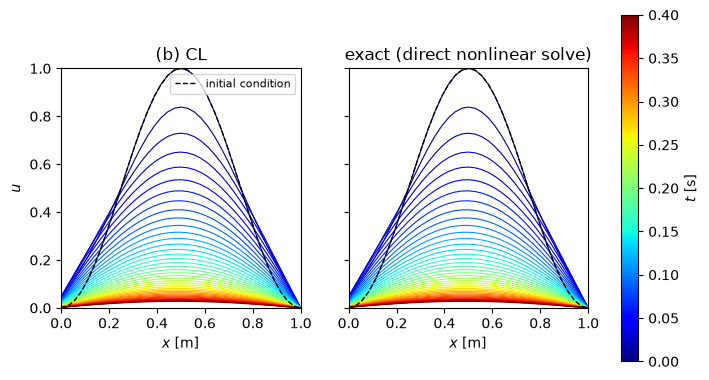

In [10]:
xp = np.concatenate([x, [1.0]])  # close the domain with the right Dirichlet node
fig, axes = plt.subplots(1, 2, figsize=(8.5, 4.5), sharey=True)
for ax, data, title in ((axes[0], cl, "(b) CL"), (axes[1], exact, "exact (direct nonlinear solve)")):
    for a, t in enumerate(times):
        ax.plot(xp, np.concatenate([data[a], [0.0]]), color=cm.jet(t / T), lw=0.8)
    ax.plot(xp, np.concatenate([u0, [0.0]]), "k--", lw=1.0, label="initial condition")
    ax.set(xlabel="$x$ [m]", xlim=(0, 1), ylim=(0, 1.0), title=title)
    ax.set_box_aspect(1)  # square panels
axes[0].set_ylabel(r"$u$")
axes[0].legend(loc="upper right", fontsize=8)
fig.colorbar(cm.ScalarMappable(cmap=cm.jet, norm=plt.Normalize(0, T)), ax=axes, label="$t$ [s]")
plt.show()

## Reading a nonlinear observable out with `lin_ode.vector`

Everything so far read $u_i$ straight out of $\boldsymbol\Phi(t)$: site $i$ *is* a basis element, so
`deg1` is only an array index.

An observable that is **not** a basis element needs its expansion coefficients. `Vector` returns
them on the same structured index the basis and matrix use, so the observable reuses the trajectory
already computed:

$$g\bigl(u(t)\bigr)=\sum_{\boldsymbol\alpha}c_{\boldsymbol\alpha}\,\boldsymbol\Phi_{\boldsymbol\alpha}(t)$$

Take the discrete Dirichlet energy, which measures roughness and must decay as diffusion smooths it:

$$E=\sum_{i=0}^{n-2}\bigl(u_{i+1}-u_i\bigr)^2
=\sum_i b_i\,u_i^2\;-\;2\!\!\sum_{\text{bonds }(i,i+1)}\!\!u_iu_{i+1}$$

| coefficient of | value | why |
|---|---|---|
| $u_i^2$ | $b_i$ | bonds touching site $i$: 1 at each end, 2 elsewhere |
| $u_iu_{i+1}$ | $-2$ | one cross term per bond |

Only monomials that can occur are queried: **71** lookups, not 9139, since sweeping the full basis
costs minutes of symbolic work.

In [11]:
# query only the monomials the expansion can touch, not all 9139 basis elements
support = [((s, 2),) for s in range(n)] + [((s, 1), (s + 1, 1)) for s in range(n - 1)]
energy = Vector(sum((u[s + 1] - u[s]) ** 2 for s in range(n - 1)), basis, u)
cols = [basis.flat_index_of_structured_index(idx) for idx in support]
weights = np.array([float(energy[idx]) for idx in support])

def monomial_str(idx):
    return " ".join(f"u_{s}^{p}" if p > 1 else f"u_{s}" for s, p in idx)

coeffs = {monomial_str(idx): int(w) for idx, w in zip(support, weights)}

print(f"{len(coeffs)} coefficients; a representative few:")
for note, idx in [
    ("end site, 1 bond", ((0, 2),)),
    ("interior site, 2 bonds", ((1, 2),)),
    ("bond (0,1)", ((0, 1), (1, 1))),
    ("far end, 1 bond", ((n - 1, 2),)),
]:
    key = monomial_str(idx)
    print(f"   {{{key}: {coeffs[key]:>3d}}}".ljust(30), f"# {note}")

71 coefficients; a representative few:
   {u_0^2:   1}                # end site, 1 bond
   {u_1^2:   2}                # interior site, 2 bonds
   {u_0 u_1:  -2}              # bond (0,1)
   {u_35^2:   1}               # far end, 1 bond


**The CL energy, from the stored trajectory.** `cols` holds where each monomial sits inside
$\boldsymbol\Phi$.

So $E(t)=\sum_\alpha c_\alpha\boldsymbol\Phi_\alpha(t)$ is one dot product per frame against the
trajectory already computed, and there is no second solve.

In [12]:
E_cl = traj[:, cols] @ weights  # one dot product per frame; traj is reused, not recomputed
print(f"E(0) = {E_cl[0]:.6f}   E(T) = {E_cl[-1]:.6f}")

E(0) = 0.136673   E(T) = 0.000087


**The same energy from the nonlinear solve.** `exact` is the direct nonlinear `solve_ivp` result
computed earlier, so evaluating $E$ on it gives the reference the degree-3 CL answer has to match.

In [13]:
E_exact = ((exact[:, 1:] - exact[:, :-1]) ** 2).sum(axis=1)
print(f"max|CL - exact| = {np.abs(E_cl - E_exact).max():.2e}")

max|CL - exact| = 1.13e-04


**Energy decay.** The scale is logarithmic, because $E$ falls by three orders of magnitude as
diffusion flattens the profile. The curves overlap until the tail, where the degree-3 truncation
becomes visible.

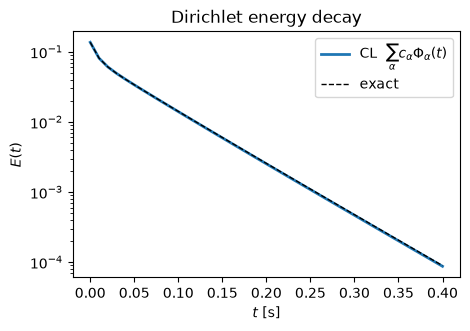

In [14]:
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.semilogy(times, E_cl, lw=2, label="CL  $\\sum_\\alpha c_\\alpha \\Phi_\\alpha(t)$")
ax.semilogy(times, E_exact, "k--", lw=1, label="exact")
ax.set(xlabel="$t$ [s]", ylabel="$E(t)$", title="Dirichlet energy decay")
ax.legend()
plt.show()

---

[← Harmonic oscillator](sho_kinetic_energy.ipynb) · [Notebook index](../README.md) · [KPP–Fisher in 2-D →](kpp_fisher_2d.ipynb)